# 02 - Nettoyage et agrégation hebdomadaire / التنظيف والتجميع الأسبوعي
Chaque étape applique une décision **validée** (Étape 3) et vérifie une **hypothèse** par le code.
Sortie finale : `outputs/sales_weekly.csv`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.forecast import data_loader as dl
from src.forecast import preprocessing as pp

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
config = dl.load_config()
params = pp.get_params(config)
PLOTS = ROOT / config["paths"]["plots_dir"]; PLOTS.mkdir(parents=True, exist_ok=True)
print("Parameters:", params)

Parameters: {'min_history_weeks': 104, 'outlier_window': 9, 'outlier_k': 6.0, 'weekly_file': 'sales_weekly.csv'}


## 1. Chargement

In [2]:
train = dl.load_train(config)
print(train.shape)

(3000888, 6)


## 2. Hypothèse : les zéros viennent de magasins fermés / pas encore ouverts
Un couple (date, magasin) est « fermé » si le magasin n'a **rien vendu, toutes familles confondues**.

In [3]:
diag = pp.zero_diagnostics(train, config)
for k, v in diag.items():
    print(f"{k}: {v}")

zero_share_pct: 31.29506999261552
zero_rows_explained_by_closed_store_days_pct: 25.756817480008092
closed_store_days: 7330
stores_with_closed_days: 54
top_stores_closed_days: {52: 1566, 22: 1011, 42: 962, 21: 934, 29: 808, 20: 773, 53: 515, 36: 131, 18: 115, 24: 106}


Lecture : `zero_rows_explained_by_closed_store_days_pct` donne la part des lignes à zéro qui s'explique par un magasin fermé.
Si elle est élevée, ces zéros ne sont **pas** de la demande nulle ; si elle est faible, les zéros restants sont réellement des familles non vendues.

## 3. Agrégation journalière, magasins ouverts, 25 décembre

daily rows: 55572 | days in file: 1684


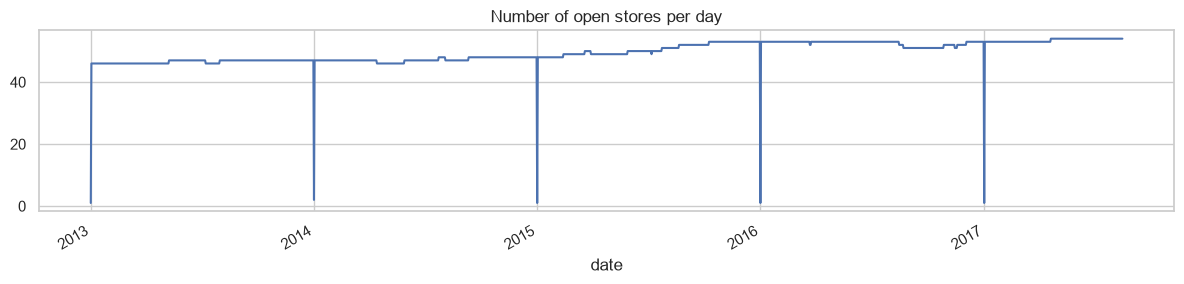

In [4]:
daily = pp.aggregate_daily(train, config)
open_stores = pp.compute_open_stores(train, config)
print("daily rows:", len(daily), "| days in file:", daily["date"].nunique())
open_stores.set_index("date")["open_stores"].plot(figsize=(12, 3), title="Number of open stores per day")
plt.tight_layout(); plt.savefig(PLOTS / "02_open_stores.png", dpi=120); plt.show()

In [5]:
daily = pp.fill_missing_calendar_days(daily, open_stores)
print("Inserted days:", sorted(d.date().isoformat() for d in daily.loc[daily["is_imputed_day"], "date"].unique()))
total = daily.groupby("date")["sales"].sum()
for year in sorted(daily.loc[daily["is_imputed_day"], "date"].dt.year.unique()):
    print(f"Total sales around 25 Dec {year}:")
    print(total[f"{year}-12-23":f"{year}-12-27"].round(0).to_string())

Inserted days: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Total sales around 25 Dec 2013:
date
2013-12-23    792865.0
2013-12-24    620663.0
2013-12-25         0.0
2013-12-26    470731.0
2013-12-27    479315.0
Total sales around 25 Dec 2014:
date
2014-12-23    1064978.0
2014-12-24     965983.0
2014-12-25          0.0
2014-12-26     872098.0
2014-12-27     740596.0
Total sales around 25 Dec 2015:
date
2015-12-23    1196146.0
2015-12-24    1083680.0
2015-12-25          0.0
2015-12-26     946725.0
2015-12-27     837714.0
Total sales around 25 Dec 2016:
date
2016-12-23    1282146.0
2016-12-24    1246838.0
2016-12-25          0.0
2016-12-26    1032771.0
2016-12-27     842475.0


## 4. Semaines (lundi) et suppression des semaines partielles

In [6]:
weekly = pp.to_weekly(daily)
weekly, partial = pp.drop_partial_weeks(weekly)
print("Removed partial weeks:", sorted({w.date().isoformat() for w in partial["week"]}))
print("Weeks per product:", weekly.groupby("product_id").size().max())

Removed partial weeks: ['2012-12-31', '2017-08-14']
Weeks per product: 240


## 5. Zéros de début de série

In [7]:
weekly, leading = pp.trim_leading_zeros(weekly)
print("Leading zero weeks removed (products concerned):")
print(leading[leading > 0].sort_values(ascending=False).to_string())

Leading zero weeks removed (products concerned):
product_id
BOOKS                         195
BABY CARE                      59
CELEBRATION                    51
HOME AND KITCHEN I             51
HOME AND KITCHEN II            51
HOME CARE                      51
LADIESWEAR                     51
MAGAZINES                      51
PET SUPPLIES                   51
PLAYERS AND ELECTRONICS        51
SCHOOL AND OFFICE SUPPLIES     51
PRODUCE                         9


## 6. Historique par produit et exclusions

In [8]:
summary = pp.history_summary(weekly)
kept, excluded = pp.select_products(summary, params["min_history_weeks"])
print(f"min_history_weeks = {params['min_history_weeks']} -> kept {len(kept)}, excluded {len(excluded)}")
print("Excluded:", excluded)
summary

min_history_weeks = 104 -> kept 32, excluded 1
Excluded: ['BOOKS']


,n_weeks,first_week,last_week,zero_weeks,mean_weekly_sales,zero_weeks_pct
product_id,,,,,,
BOOKS,45,2016-10-03,2017-08-07,0,143.1,0.0
BABY CARE,181,2014-02-24,2017-08-07,41,55.4,22.7
CELEBRATION,189,2013-12-30,2017-08-07,40,4021.1,21.2
HOME AND KITCHEN I,189,2013-12-30,2017-08-07,19,9831.4,10.1
MAGAZINES,189,2013-12-30,2017-08-07,31,1404.4,16.4
LADIESWEAR,189,2013-12-30,2017-08-07,40,3440.0,21.2
HOME CARE,189,2013-12-30,2017-08-07,36,84631.1,19.0
HOME AND KITCHEN II,189,2013-12-30,2017-08-07,19,8029.4,10.1
SCHOOL AND OFFICE SUPPLIES,189,2013-12-30,2017-08-07,40,1396.6,21.2


## 7. Valeurs extrêmes (marquées, jamais modifiées)

In [9]:
weekly = weekly[weekly["product_id"].isin(kept)].reset_index(drop=True)
weekly["is_outlier"] = pp.flag_outliers(weekly, params["outlier_window"], params["outlier_k"])
print("Flagged weeks:", int(weekly["is_outlier"].sum()), "of", len(weekly))
weekly[weekly["is_outlier"]].sort_values("sales", ascending=False).head(15)[["product_id", "week", "sales", "open_stores"]]

Flagged weeks: 244 of 7153


,product_id,week,sales,open_stores
2701,GROCERY I,2016-04-18,2.766046e+06,53.0
832,BEVERAGES,2016-04-18,1.730603e+06,53.0
869,BEVERAGES,2017-01-02,1.714281e+06,53.0
721,BEVERAGES,2014-03-03,1.082450e+06,47.0
724,BEVERAGES,2014-03-24,9.598180e+05,47.0
723,BEVERAGES,2014-03-17,9.523450e+05,47.0
722,BEVERAGES,2014-03-10,9.426690e+05,47.0
6544,PRODUCE,2014-03-03,8.064799e+05,47.0
6536,PRODUCE,2014-01-06,7.773969e+05,47.0
6537,PRODUCE,2014-01-13,7.470700e+05,47.0


In [10]:
# Are the April 2016 peaks linked to a registered event? (look for it in holidays_events.csv)
holidays = dl.load_holidays(config)
mask = holidays["description"].str.contains("Terremoto|earthquake", case=False, regex=True)
holidays.loc[mask, ["date", "type", "locale", "locale_name", "description"]].head(20)

,date,type,locale,locale_name,description
219,2016-04-16,Event,National,Ecuador,Terremoto Manabi
220,2016-04-17,Event,National,Ecuador,Terremoto Manabi+1
221,2016-04-18,Event,National,Ecuador,Terremoto Manabi+2
222,2016-04-19,Event,National,Ecuador,Terremoto Manabi+3
223,2016-04-20,Event,National,Ecuador,Terremoto Manabi+4
225,2016-04-21,Event,National,Ecuador,Terremoto Manabi+5
226,2016-04-22,Event,National,Ecuador,Terremoto Manabi+6
227,2016-04-23,Event,National,Ecuador,Terremoto Manabi+7
228,2016-04-24,Event,National,Ecuador,Terremoto Manabi+8
229,2016-04-25,Event,National,Ecuador,Terremoto Manabi+9


## 8. Visualisation

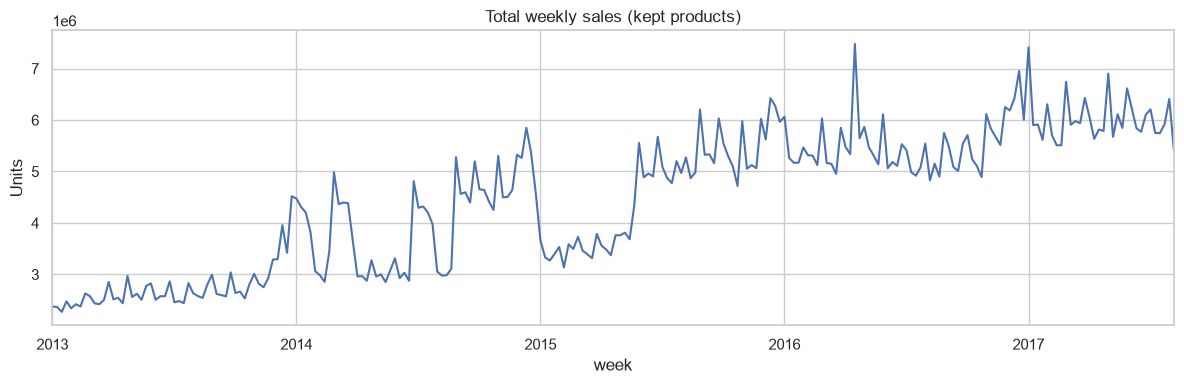

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
weekly.groupby("week")["sales"].sum().plot(ax=ax)
ax.set_title("Total weekly sales (kept products)"); ax.set_ylabel("Units")
plt.tight_layout(); plt.savefig(PLOTS / "02_weekly_total.png", dpi=120); plt.show()

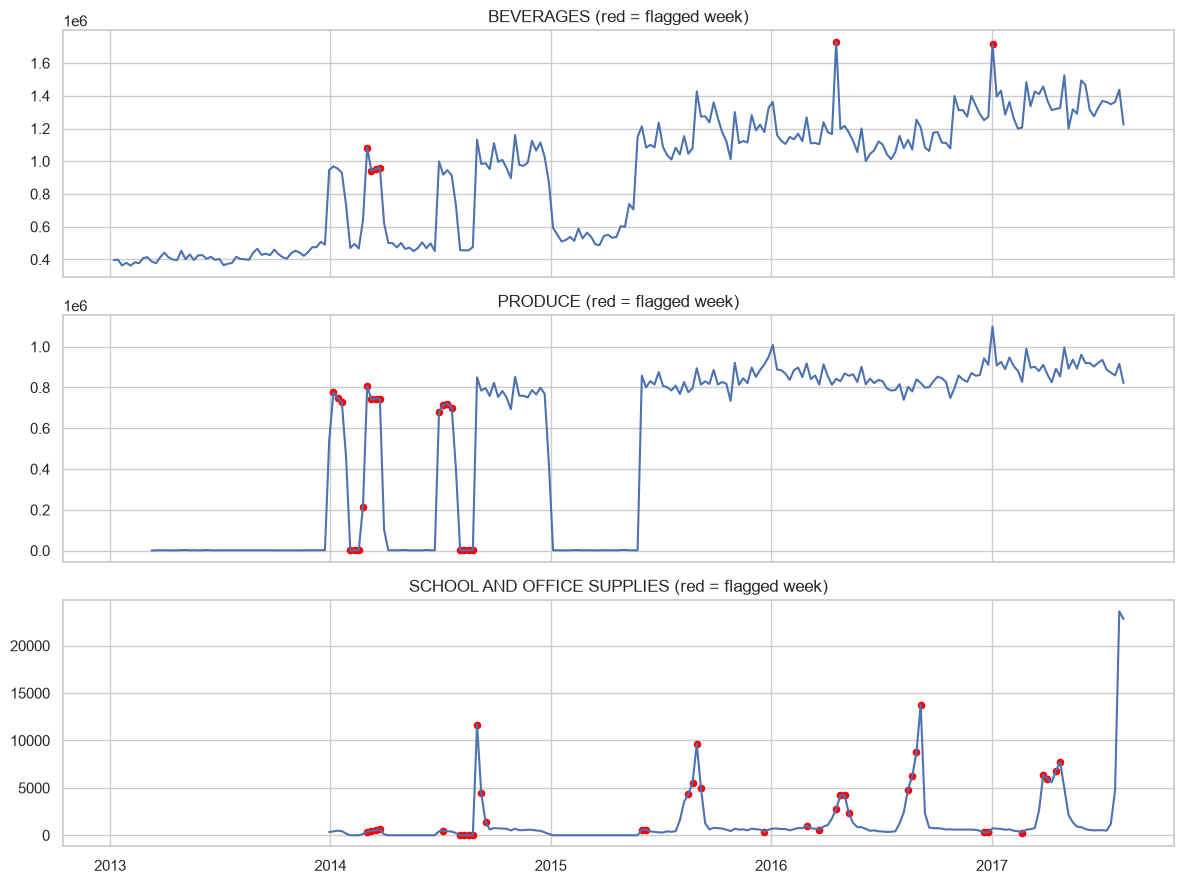

In [12]:
examples = [p for p in ["BEVERAGES", "PRODUCE", "BOOKS", "SCHOOL AND OFFICE SUPPLIES"] if p in kept] or kept[:4]
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 3 * len(examples)), sharex=True)
for ax, pid in zip(axes if len(examples) > 1 else [axes], examples):
    g = weekly[weekly["product_id"] == pid]
    ax.plot(g["week"], g["sales"]); ax.scatter(g.loc[g["is_outlier"], "week"], g.loc[g["is_outlier"], "sales"], color="red", s=20)
    ax.set_title(f"{pid} (red = flagged week)")
plt.tight_layout(); plt.savefig(PLOTS / "02_weekly_examples.png", dpi=120); plt.show()

## 9. Écriture des fichiers (même code que `python -m src.forecast.preprocessing`)

In [13]:
result = pp.run_preprocessing(config, train=train)
for k, v in result["report"].items():
    print(f"{k}: {v}")
pd.read_csv(ROOT / config["paths"]["outputs_dir"] / params["weekly_file"]).head()

days_in_file: 1684
days_inserted: 4
partial_weeks_removed: 2
leading_zero_weeks_removed: 722
products_kept: ['BABY CARE', 'CELEBRATION', 'HOME AND KITCHEN I', 'MAGAZINES', 'LADIESWEAR', 'HOME CARE', 'HOME AND KITCHEN II', 'SCHOOL AND OFFICE SUPPLIES', 'PLAYERS AND ELECTRONICS', 'PET SUPPLIES', 'PRODUCE', 'BEVERAGES', 'BEAUTY', 'BREAD/BAKERY', 'AUTOMOTIVE', 'HARDWARE', 'GROCERY II', 'GROCERY I', 'FROZEN FOODS', 'DELI', 'EGGS', 'DAIRY', 'CLEANING', 'LIQUOR,WINE,BEER', 'LINGERIE', 'LAWN AND GARDEN', 'HOME APPLIANCES', 'MEATS', 'PERSONAL CARE', 'PREPARED FOODS', 'POULTRY', 'SEAFOOD']
products_excluded: ['BOOKS']
products_never_sold: []
weeks_in_output: 7153
outlier_weeks: 244


,product_id,week,sales,onpromotion,open_stores,is_outlier
0,AUTOMOTIVE,2013-01-07,1514.0,0.0,46.0,False
1,AUTOMOTIVE,2013-01-14,1511.0,0.0,46.0,False
2,AUTOMOTIVE,2013-01-21,1517.0,0.0,46.0,False
3,AUTOMOTIVE,2013-01-28,1807.0,0.0,46.0,False
4,AUTOMOTIVE,2013-02-04,1940.0,0.0,46.0,False


## 10. Décisions appliquées / القرارات المطبقة
| Décision | Fonction |
|---|---|
| `product_id = family`, somme sur les 54 magasins | `aggregate_daily` |
| 25 décembre inséré avec ventes = 0 (pas de mise à l'échelle) | `fill_missing_calendar_days` |
| Semaines du lundi, semaines partielles supprimées | `to_weekly`, `drop_partial_weeks` |
| Zéros avant la première vente supprimés | `trim_leading_zeros` |
| Produits à historique court exclus (liste dans `excluded_products.csv`) | `select_products` |
| Valeurs extrêmes marquées (`is_outlier`), jamais supprimées | `flag_outliers` |
| Magasins ouverts conservés comme variable (`open_stores`) | `compute_open_stores` |